# Viz discriminator: can a classifier tell real walks from synthetic walks?

A classifier two-sample test (`docs/realfake/PLAN.md`, `docs/realfake/snap.md`): a model is trained to tell
random-walk subgraphs cut from the **real** ego-Facebook graph from walks cut from a **synthetic** graph, on
features that drop representation details (node ids, ordering, column order) and keep everything the method is
supposed to model (degrees, structure, attributes).

How to read AUC: **0.5 means this model cannot tell real from synthetic**, 1.0 means trivially detectable. The
real-vs-real control (one half of the real graph against the other) is the achievable floor - here 0.515 (logreg)
/ 0.528 (gbm) - and the non-private baselines (Erdos-Renyi, Chung-Lu, DC-SBM, BTER) mark the easy-to-detect end.
A good method would sit near the real-vs-real line, far below the baselines.

This notebook only plots the result tables in `snap/eval/results/discriminator*.csv`, written by stage-3
`snap/eval/discriminate.py` (n = 2000 walks per label per method, 3 folds rotating the held-out fake generation
seed, real walks group-split by start node, permuted-label control per fold). Write-up:
`snap/reports/discriminator_v1.md`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from IPython.display import display

NB = Path.cwd()
EVAL = NB.parent if NB.name == "notebooks" else NB          # snap/eval
RESULTS = EVAL / "results"

plt.rcParams["figure.dpi"] = 110


def show(fig):
    # display explicitly (works on any backend), then free the figure
    display(fig)
    plt.close(fig)


summary = pd.read_csv(RESULTS / "discriminator_summary.csv")       # mean/std over folds per (method, eps, model)
importance = pd.read_csv(RESULTS / "discriminator_importance.csv") # permutation importance per feature group
by_size = pd.read_csv(RESULTS / "discriminator_by_size.csv")       # AUC per walk-size bucket (strongest model)
folds = pd.read_csv(RESULTS / "discriminator.csv")                 # one row per (method, eps, fold, model)

# strongest model per (method, epsilon): the claim is always the strongest model (docs/realfake/PLAN.md section 4)
best = (
    summary.loc[summary.groupby(["method", summary["epsilon"].fillna(-1.0)])["auc_mean"].idxmax()]
    .sort_values(["method", "epsilon"])
    .reset_index(drop=True)
)

# fixed colour per method (identity), fixed order; black = control, as in viz_comparison
C = {
    "graph_aim": "#0072B2",
    "graph_aim_nocap_nonprivate": "#56B4E9",
    "erdos_renyi": "#E69F00",
    "chung_lu": "#D55E00",
    "dc_sbm": "#009E73",
    "bter": "#CC79A7",
}
BASELINES = ["erdos_renyi", "chung_lu", "dc_sbm", "bter"]
rvr = {m: summary.query("method == 'real_vs_real' and model == @m")["auc_mean"].iloc[0] for m in ("logreg", "gbm")}

for _, r in best.iterrows():
    eps = "-" if pd.isna(r.epsilon) else r.epsilon
    print(f"{r.method:28s} eps {eps!s:6s} {r.model:6s} AUC {r.auc_mean:.4f} +- {0 if pd.isna(r.auc_std) else r.auc_std:.4f}")

bter                         eps -      gbm    AUC 0.9993 +- 0.0010
chung_lu                     eps -      logreg AUC 1.0000 +- 0.0000
dc_sbm                       eps -      gbm    AUC 0.9999 +- 0.0001
erdos_renyi                  eps -      logreg AUC 1.0000 +- 0.0000
graph_aim                    eps 0.5    gbm    AUC 0.9999 +- 0.0002
graph_aim                    eps 1.0    gbm    AUC 0.9999 +- 0.0001
graph_aim                    eps 2.0    gbm    AUC 0.9994 +- 0.0009
graph_aim                    eps 4.0    gbm    AUC 0.9998 +- 0.0001
graph_aim                    eps 8.0    gbm    AUC 0.9999 +- 0.0001
graph_aim                    eps inf    gbm    AUC 0.9999 +- 0.0001
graph_aim_nocap_nonprivate   eps inf    gbm    AUC 0.9999 +- 0.0000
real_vs_real                 eps -      gbm    AUC 0.5285 +- 0.0000


## 1. AUC against epsilon

Left: raw AUC on a linear axis - every method against the controls. Right: the same numbers as **1 - AUC on a log
axis** (gbm for every method, so no exact 1.0000 falls off the scale), because all the synthetic graphs sit so
close to 1.0 that only a log view separates them; lower = more detectable, and the real-vs-real control at the top
is the floor a faithful method should approach. *Look for:* does the graph_aim curve fall toward the control as
epsilon grows?

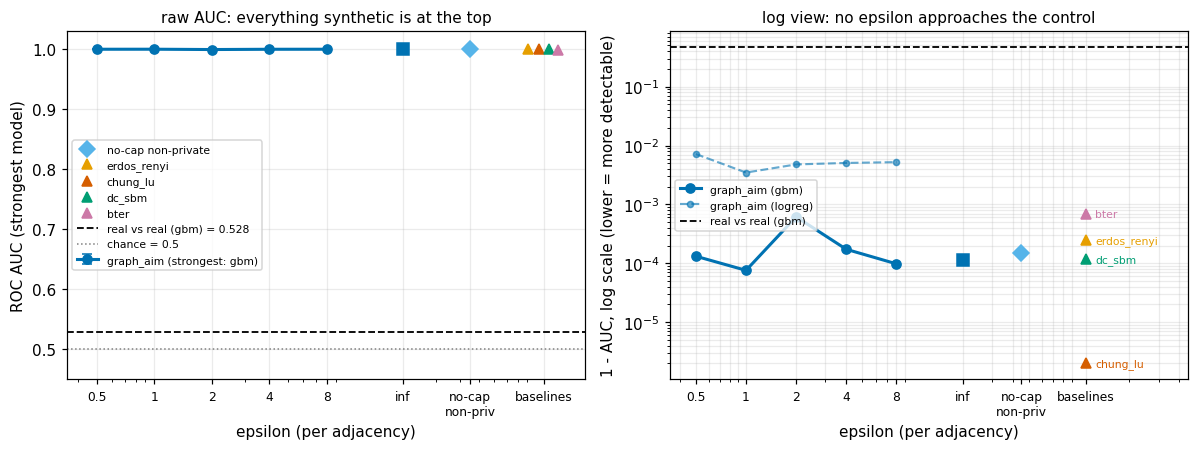

In [2]:
FIN = [0.5, 1.0, 2.0, 4.0, 8.0]
X_INF, X_NOCAP, X_BASE = 20.0, 45.0, 110.0  # off-curve slots on the log x-axis
XTICKS = FIN + [X_INF, X_NOCAP, X_BASE]
XLABELS = ["0.5", "1", "2", "4", "8", "inf", "no-cap\nnon-priv", "baselines"]

ga = best.query("method == 'graph_aim'")
fin = ga[np.isfinite(ga.epsilon)].sort_values("epsilon")
inf_row = ga[np.isinf(ga.epsilon)].iloc[0]
nocap = best.query("method == 'graph_aim_nocap_nonprivate'").iloc[0]

fig, (ax, bx) = plt.subplots(1, 2, figsize=(11, 4.2))

# --- left: raw AUC, linear ---
ax.errorbar(fin.epsilon, fin.auc_mean, yerr=fin.auc_std, color=C["graph_aim"], lw=2, marker="o", ms=6,
            capsize=3, label="graph_aim (strongest: gbm)")
ax.plot([X_INF], [inf_row.auc_mean], "s", ms=8, color=C["graph_aim"])
ax.plot([X_NOCAP], [nocap.auc_mean], "D", ms=7, color=C["graph_aim_nocap_nonprivate"], label="no-cap non-private")
for i, m in enumerate(BASELINES):
    r = best.query("method == @m").iloc[0]
    ax.plot([X_BASE * (1 + 0.12 * (i - 1.5))], [r.auc_mean], "^", ms=7, color=C[m], label=m)
ax.axhline(rvr["gbm"], color="black", ls="--", lw=1.2, label=f"real vs real (gbm) = {rvr['gbm']:.3f}")
ax.axhline(0.5, color="gray", ls=":", lw=1, label="chance = 0.5")
ax.set_xscale("log")
ax.set_xticks(XTICKS, XLABELS, fontsize=8)
ax.set_xlim(0.35, 180)
ax.set_ylim(0.45, 1.03)
ax.set_xlabel("epsilon (per adjacency)")
ax.set_ylabel("ROC AUC (strongest model)")
ax.set_title("raw AUC: everything synthetic is at the top", fontsize=10)
ax.legend(fontsize=7, loc="center left")
ax.grid(alpha=0.25)

# --- right: 1 - AUC, log (gbm everywhere; logreg logs exact 1.0 for ER/CL) ---
gbm = summary.query("model == 'gbm'")
gfin = gbm.query("method == 'graph_aim'")[np.isfinite(gbm.query("method == 'graph_aim'").epsilon)].sort_values("epsilon")
ginf = gbm.query("method == 'graph_aim'")[np.isinf(gbm.query("method == 'graph_aim'").epsilon)].iloc[0]
gnocap = gbm.query("method == 'graph_aim_nocap_nonprivate'").iloc[0]
lfin = summary.query("model == 'logreg' and method == 'graph_aim'")
lfin = lfin[np.isfinite(lfin.epsilon)].sort_values("epsilon")

bx.plot(gfin.epsilon, 1 - gfin.auc_mean, color=C["graph_aim"], lw=2, marker="o", ms=6, label="graph_aim (gbm)")
bx.plot(lfin.epsilon, 1 - lfin.auc_mean, color=C["graph_aim"], lw=1.4, ls="--", marker="o", ms=4, alpha=0.6,
        label="graph_aim (logreg)")
bx.plot([X_INF], [1 - ginf.auc_mean], "s", ms=8, color=C["graph_aim"])
bx.plot([X_NOCAP], [1 - gnocap.auc_mean], "D", ms=7, color=C["graph_aim_nocap_nonprivate"])
for m in BASELINES:
    r = gbm.query("method == @m").iloc[0]
    bx.plot([X_BASE], [1 - r.auc_mean], "^", ms=7, color=C[m])
    bx.annotate(m, (X_BASE, 1 - r.auc_mean), xytext=(6, -2), textcoords="offset points", fontsize=7, color=C[m])
bx.axhline(1 - rvr["gbm"], color="black", ls="--", lw=1.2, label="real vs real (gbm)")
bx.set_xscale("log")
bx.set_yscale("log")
bx.set_xticks(XTICKS, XLABELS, fontsize=8)
bx.set_xlim(0.35, 450)
bx.set_xlabel("epsilon (per adjacency)")
bx.set_ylabel("1 - AUC, log scale (lower = more detectable)")
bx.set_title("log view: no epsilon approaches the control", fontsize=10)
bx.legend(fontsize=7, loc="center left")
bx.grid(alpha=0.25, which="both")

fig.tight_layout()
show(fig)

**What we see.** Every graph_aim variant is near-perfectly detectable: gradient boosting reaches AUC
0.9994-0.9999 at *every* epsilon, including eps = inf and the no-cap non-private variant; plain logistic
regression alone gets 0.993-0.997. The controls say the pipeline is sound: real-vs-real sits at 0.515 / 0.528
(logreg / gbm), permuted labels at ~0.5 (gbm 0.47-0.55 over folds), and the baselines fill the easy end
(Erdos-Renyi and Chung-Lu at logreg AUC 1.0000). On the log panel the graph_aim curve is flat and four orders of
magnitude below the real-vs-real control: at walk level the gap to the real graph comes from the generator, not
from the privacy noise. This is a fidelity finding that the scalar metrics and the 0.99-everywhere
link-prediction utility (`docs/snap/PROCESS.md` D12) hid - and it is not a privacy statement either way.

## 2. What gives it away: permutation importance by feature group

Each line is a feature group of the featurizer (`docs/realfake/snap.md` section 3); the value is how much AUC the
gbm loses when that group's columns are shuffled in the test fold (fold 0). Log scale, because attributes dwarf
the rest; values within noise of zero are clipped to the axis floor (1e-6).

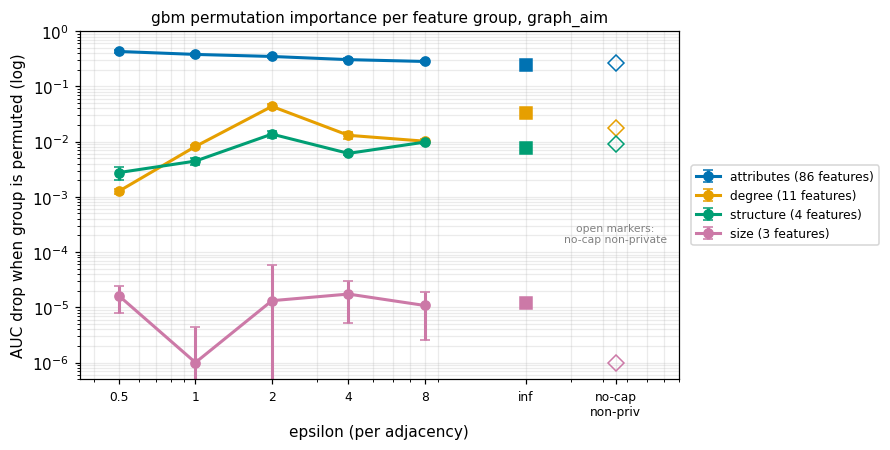

In [3]:
GROUPS = ["attributes", "degree", "structure", "size"]
GC = {"attributes": "#0072B2", "degree": "#E69F00", "structure": "#009E73", "size": "#CC79A7"}
FLOOR = 1e-6

imp = importance.query("method == 'graph_aim'")
imp_nocap = importance.query("method == 'graph_aim_nocap_nonprivate'")

fig, ax = plt.subplots(figsize=(8.2, 4.2))
for g in GROUPS:
    d = imp.query("group == @g")
    dfin = d[np.isfinite(d.epsilon)].sort_values("epsilon")
    dinf = d[np.isinf(d.epsilon)].iloc[0]
    dnc = imp_nocap.query("group == @g").iloc[0]
    ax.errorbar(dfin.epsilon, dfin.auc_drop.clip(lower=FLOOR), yerr=dfin.auc_drop_std,
                color=GC[g], lw=2, marker="o", ms=6, capsize=3, label=f"{g} ({int(dfin.n_features.iloc[0])} features)")
    ax.plot([X_INF], [max(dinf.auc_drop, FLOOR)], "s", ms=8, color=GC[g])
    ax.plot([X_NOCAP], [max(dnc.auc_drop, FLOOR)], "D", ms=7, mfc="none", color=GC[g])
ax.annotate("open markers:\nno-cap non-private", (X_NOCAP, 1.5e-4), fontsize=7, ha="center", color="gray")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xticks([*FIN, X_INF, X_NOCAP], ["0.5", "1", "2", "4", "8", "inf", "no-cap\nnon-priv"], fontsize=8)
ax.set_xlim(0.35, 80)
ax.set_ylim(FLOOR * 0.5, 1)
ax.set_xlabel("epsilon (per adjacency)")
ax.set_ylabel("AUC drop when group is permuted (log)")
ax.set_title("gbm permutation importance per feature group, graph_aim", fontsize=10)
ax.legend(fontsize=8, loc="center left", bbox_to_anchor=(1.01, 0.5))
ax.grid(alpha=0.25, which="both")
fig.tight_layout()
show(fig)

**What we see.** The epsilon gradient that the AUC hides lives here: permuting the **attributes** group costs
0.43 AUC at eps 0.5 and falls monotonically to 0.24 at eps = inf (0.26 for no-cap non-private) - more budget does
make the attribute statistics more faithful, just never faithful enough to lower the AUC. Degree is a distant
second (0.001-0.043), structure stays below 0.014, and size is zero to within noise (by construction: the sampler
draws the same size distribution for both labels). So walk-level attribute statistics - marginal shares,
`none`/`other` shares, same-value edge rates, attribute-pair co-occurrence on edges - are the giveaway at every
epsilon.

**Caveat.** The attributes group mixes genuine statistics with a candidate generation artifact: exact
`none`/`other` code shares, the open point in `docs/realfake/snap.md` section 2 (issue 1 in
`docs/realfake/PROCESS.md`). Splitting the group per feature is follow-up work; until then "attributes dominate"
must **not** be read as "homophily is the sole cause".

## 3. AUC by walk size

AUC of the strongest model recomputed inside each walk-size bucket (k = distinct nodes visited; fold 0). Blues
dark with epsilon for graph_aim; dashed = non-private references. *Look for:* is there any sample size at which
the synthetic walks pass?

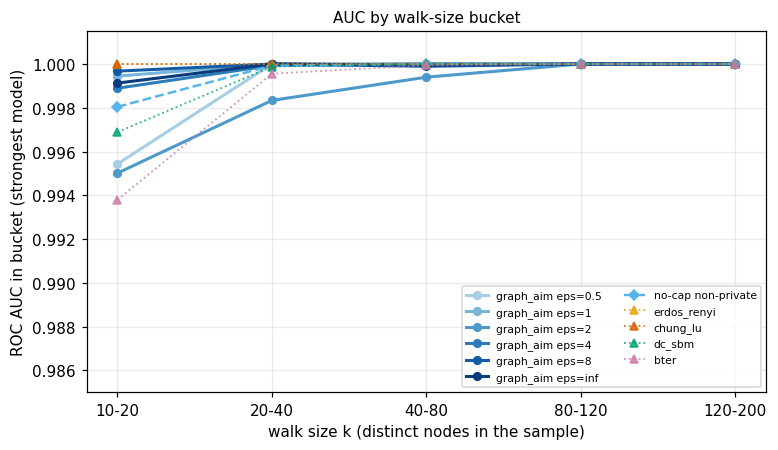

minimum bucket AUC over all methods: 0.9938  (graph_aim only: 0.9950, both in the 10-20 bucket)


In [4]:
BUCKETS = ["10-20", "20-40", "40-80", "80-120", "120-200"]

ga_sz = by_size.query("method == 'graph_aim'")
eps_vals = sorted(ga_sz.epsilon.unique())
blues = plt.cm.Blues(np.linspace(0.35, 0.95, len(eps_vals)))

fig, ax = plt.subplots(figsize=(7.2, 4.2))
for c, e in zip(blues, eps_vals):
    d = ga_sz[ga_sz.epsilon == e].sort_values("lo")
    lab = "graph_aim eps=inf" if np.isinf(e) else f"graph_aim eps={e:g}"
    ax.plot(range(len(d)), d.auc, color=c, lw=2, marker="o", ms=5, label=lab)
d = by_size.query("method == 'graph_aim_nocap_nonprivate'").sort_values("lo")
ax.plot(range(len(d)), d.auc, color=C["graph_aim_nocap_nonprivate"], lw=1.6, ls="--", marker="D", ms=5,
        label="no-cap non-private")
for m in BASELINES:
    d = by_size.query("method == @m").sort_values("lo")
    ax.plot(range(len(d)), d.auc, color=C[m], lw=1.2, ls=":", marker="^", ms=5, alpha=0.8, label=m)
ax.set_xticks(range(len(BUCKETS)), BUCKETS)
ax.set_xlabel("walk size k (distinct nodes in the sample)")
ax.set_ylabel("ROC AUC in bucket (strongest model)")
ax.set_ylim(0.985, 1.0015)
ax.set_title("AUC by walk-size bucket", fontsize=10)
ax.legend(fontsize=7, ncol=2, loc="lower right")
ax.grid(alpha=0.25)
fig.tight_layout()
show(fig)
print(f"minimum bucket AUC over all methods: {by_size.auc.min():.4f}  "
      f"(graph_aim only: {ga_sz.auc.min():.4f}, both in the 10-20 bucket)")

**What we see.** AUC stays at or above 0.995 in every bucket for every graph_aim variant, slightly lowest in the
smallest bucket (k 10-20) and indistinguishable from 1.0 beyond k = 80. More walk is more evidence, but even the
smallest samples already give the classifier enough - there is no sample size at which the synthetic walks pass.

## 4. The numbers behind the pictures

Strongest model per method (over folds; fold = held-out fake generation seed). `permuted` is the label-permutation
control on the same folds, `real_vs_real` the leakage control for that model class. Raw tables:
`snap/eval/results/discriminator*.csv`.

In [5]:
ORDER = ["graph_aim", "graph_aim_nocap_nonprivate", "erdos_renyi", "chung_lu", "dc_sbm", "bter", "real_vs_real"]
tbl = best.copy()
tbl["AUC (mean +- std)"] = tbl.apply(
    lambda r: f"{r.auc_mean:.4f}" + ("" if pd.isna(r.auc_std) else f" +- {r.auc_std:.4f}"), axis=1)
tbl["epsilon"] = tbl.epsilon.map(lambda e: "-" if pd.isna(e) else ("inf" if np.isinf(e) else f"{e:g}"))
tbl["permuted"] = tbl.permuted_auc_mean.round(3)
tbl["real_vs_real"] = tbl.real_vs_real_auc_mean.round(3)
tbl["accuracy"] = tbl.accuracy_mean.round(3)
tbl = tbl.set_index("method").loc[ORDER].reset_index()  # best is already epsilon-sorted within a method
tbl[["method", "epsilon", "model", "AUC (mean +- std)", "permuted", "real_vs_real", "accuracy"]]

,method,epsilon,model,AUC (mean +- std),permuted,real_vs_real,accuracy
0,graph_aim,0.5,gbm,0.9999 +- 0.0002,0.554,0.528,0.984
1,graph_aim,1,gbm,0.9999 +- 0.0001,0.516,0.528,0.987
2,graph_aim,2,gbm,0.9994 +- 0.0009,0.503,0.528,0.967
3,graph_aim,4,gbm,0.9998 +- 0.0001,0.484,0.528,0.992
4,graph_aim,8,gbm,0.9999 +- 0.0001,0.520,0.528,0.995
5,graph_aim,inf,gbm,0.9999 +- 0.0001,0.473,0.528,0.994
6,graph_aim_nocap_nonprivate,inf,gbm,0.9999 +- 0.0000,0.497,0.528,0.995
7,erdos_renyi,-,logreg,1.0000 +- 0.0000,0.430,0.515,1.000
8,chung_lu,-,logreg,1.0000 +- 0.0000,0.424,0.515,0.999
9,dc_sbm,-,gbm,0.9999 +- 0.0001,0.478,0.528,0.994


## Caveats

- **Detectability is a fidelity statement at walk level, not a privacy failure.** The DP guarantee is unchanged;
  a *failed* discriminator would have been evidence of fidelity, not of privacy.
- The strongest model is reported by design (`docs/realfake/PLAN.md` section 4); a weaker model's 0.99 would
  flatter the method, not clear it.
- One real graph: all folds share it (folds rotate the held-out fake seed; real walks are group-split by start
  node). The real-vs-real and permuted-label controls bound what that sharing can leak.
- The attributes importance group is not yet split per feature; the `none`/`other` share artifact question
  (`docs/realfake/PROCESS.md` issue 1) is open.